# Лабораторная работа № 1
## Иерархический кластерный анализ

**Вариант 2 — Economics of Cities**

### Цель работы

Определить количество кластеров городов на основе экономических показателей, распределить города по полученным группам и предложить интерпретацию кластеров.

### Постановка задачи

Провести иерархическую кластеризацию 48 городов мира по показателям продолжительности рабочего времени, уровня цен и почасовой заработной платы. Обосновать выбор количества кластеров и проанализировать полученные группы.

### Описание данных

Набор данных содержит экономические показатели 48 городов мира за 1991 год:

- **City** — название города;
- **Work** — средневзвешенное количество рабочих часов по 12 профессиям;
- **Price** — индекс цен на 112 товаров и услуг, включая аренду жилья;
- **Salary** — индекс почасовой заработной платы после налогов и вычетов по 12 профессиям.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(
    "/content/Econom_Cities_data.csv",
    sep=";",
    decimal=","
)
df.head()

,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5
3,Bombay,2052,30.3,5.3
4,Brussels,1708,73.8,50.5


In [3]:
# Информация о данных
df.info()
print(df.isna().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   City    48 non-null     object 
 1   Work    48 non-null     int64  
 2   Price   48 non-null     float64
 3   Salary  48 non-null     float64
dtypes: float64(2), int64(1), object(1)
memory usage: 1.6+ KB
City      0
Work      0
Price     0
Salary    0
dtype: int64


,Work,Price,Salary
count,48.000000,48.000000,48.000000
mean,1384.958333,68.860417,-378.727083
std,2404.897007,21.784659,2027.338052
min,-9999.000000,30.300000,-9999.000000
25%,1740.750000,49.650000,12.250000
50%,1834.500000,70.500000,40.300000
75%,1972.750000,81.700000,58.700000
max,2375.000000,115.500000,100.000000


In [4]:
df[(df[["Work", "Price", "Salary"]] < 0).any(axis=1)]

,City,Work,Price,Salary
6,Cairo,-9999,37.1,-9999.0
17,Jakarta,-9999,43.6,-9999.0


Первоначальная проверка показала, что набор содержит 48 наблюдений и 4 переменные. Все столбцы имеют корректные типы данных, стандартные пропуски (NaN) отсутствуют.

При анализе описательной статистики были выявлены значения -9999 в признаках Work и Salary для двух городов — Cairo и Jakarta.

In [5]:
df_clean = df.drop(
    df[(df["Work"] == -9999) | (df["Salary"] == -9999)].index
).copy()

После очистки данных проведём визуальный анализ показателей.
Для этого построим гистограммы распределений признаков Work, Price и Salary. Это позволит оценить диапазоны значений, особенности распределений и возможное наличие выбросов.

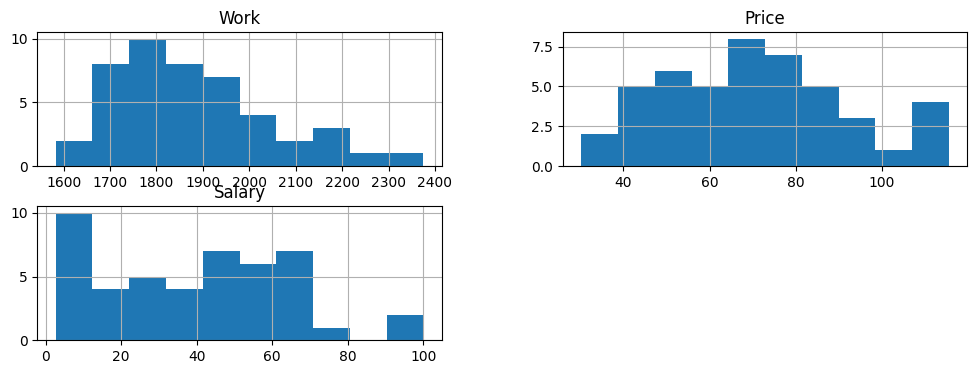

In [6]:
features = ["Work", "Price", "Salary"]

df_clean[features].hist(figsize=(12, 4), bins=10)
plt.show()

**Work:** большинство городов имеет примерно 1650–2000 рабочих часов. Распределение смещено вправо, встречаются отдельные значения до 2400 часов.

**Price:** индекс цен изменяется примерно от 30 до 115. Наибольшая концентрация городов наблюдается в диапазоне 60–80.

**Salary:** индекс заработной платы имеет значительный разброс — примерно от 3 до 100. Заметна концентрация городов с низкими зарплатами (до 20), а также в диапазоне 40–70.

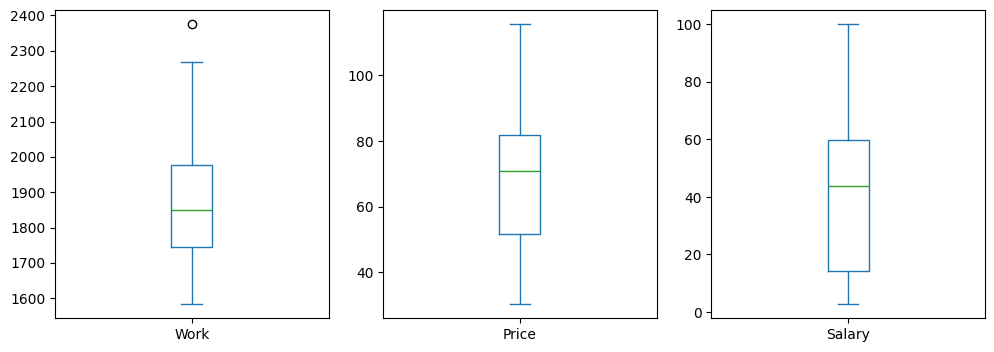

In [7]:
df_clean[features].plot(
    kind="box",
    subplots=True,
    layout=(1, 3),
    figsize=(12, 4)
)
plt.show()

**Распределения и выбросы**
Показатели городов имеют различные диапазоны значений. На Boxplot обнаружен один потенциальный выброс по признаку Work. Для Price и Salary потенциальных выбросов не выявлено. Наблюдение с высоким Work пока оставил, поскольку его значение не обязательно говорит об ошибке.

In [8]:
corr_matrix = df_clean[features].corr()

corr_matrix.round(2)

,Work,Price,Salary
Work,1.00,-0.45,-0.46
Price,-0.45,1.00,0.80
Salary,-0.46,0.80,1.00


**Взаимосвязи признаков**
Между Price и Salary наблюдается сильная положительная корреляция (0.80). Признак Work имеет умеренную отрицательную корреляцию с Price (−0.45) и Salary (−0.46).

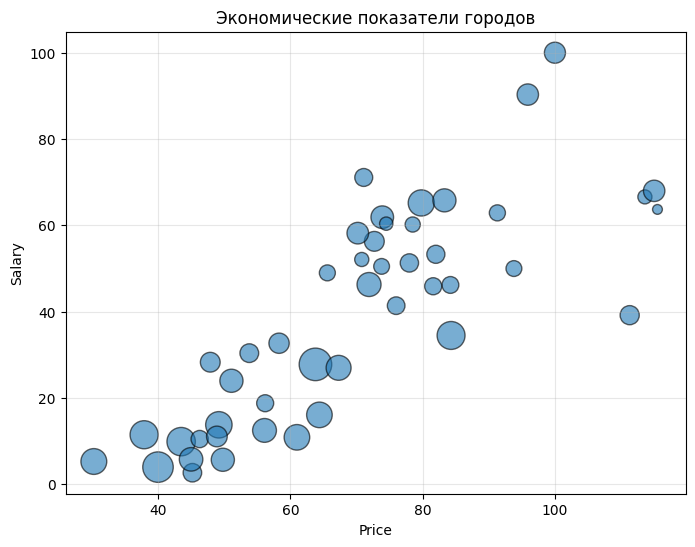

In [9]:
work = df_clean["Work"]
sizesMM = 50 + (work - work.min()) / (work.max() - work.min()) * 500

plt.figure(figsize=(8, 6))

plt.scatter(
    df_clean["Price"],
    df_clean["Salary"],
    s=sizesMM,
    alpha=0.6,
    edgecolors="black"
)

plt.xlabel("Price")
plt.ylabel("Salary")
plt.title("Экономические показатели городов")
plt.grid(alpha=0.3)
plt.show()


**Пузырьковая диаграмма**
Города с низкими ценами и зарплатами преимущественно имеют более крупные пузырьки, что указывает на относительно высокое количество рабочих часов. Для городов с более высокими зарплатами и ценами чаще характерны меньшие значения.

Перед кластеризацией выполним стандартизацию признаков Work, Price и Salary методом Z-score. Это позволяет использовать их совместно при проведении кластерного анализа.

In [10]:
X = df_clean[features]
X_scaled = (X - X.mean()) / X.std()
print(X_scaled.describe().round(2))
X_scaled.head()

        Work  Price  Salary
count  46.00  46.00   46.00
mean    0.00  -0.00    0.00
std     1.00   1.00    1.00
min    -1.70  -1.86   -1.49
25%    -0.77  -0.86   -1.02
50%    -0.18   0.04    0.17
75%     0.55   0.55    0.81
max     2.84   2.12    2.44


,Work,Price,Salary
0,-0.951650,-0.210387,0.381875
1,-0.504255,-0.762068,-0.369406
2,1.560646,-1.505434,-1.132805
3,0.987062,-1.860754,-1.383232
4,-0.986065,0.172985,0.442462


###Кластеризация методом DBSCAN

DBSCAN группирует города по плотности их расположения в пространстве признаков и позволяет выделять шумовые объекты. Количество кластеров заранее не задаётся.

Для кластеризации необходимо подобрать два параметра: eps — радиус окрестности и min_samples — минимальное число объектов в ней, включая сам объект.

**Подбор параметров DBSCAN**

Для предварительного выбора параметра eps используем метод k-distance - анализ расстояний до ближайших соседей.

Построим три графика для min_samples = 3, 4, 5. Для каждого города рассчитывается расстояние до соответствующего соседа, после чего значения сортируются по возрастанию.

При подсчёте соседей учитывается сам объект, поэтому для min_samples = 4 рассматривается расстояние до третьего другого города.

Поскольку анализ проводится по трём признакам, значение min_samples = 4 выбрано как начальный ориентир по эвристике D + 1. Дополнительно рассматриваются соседние значения 3 и 5.

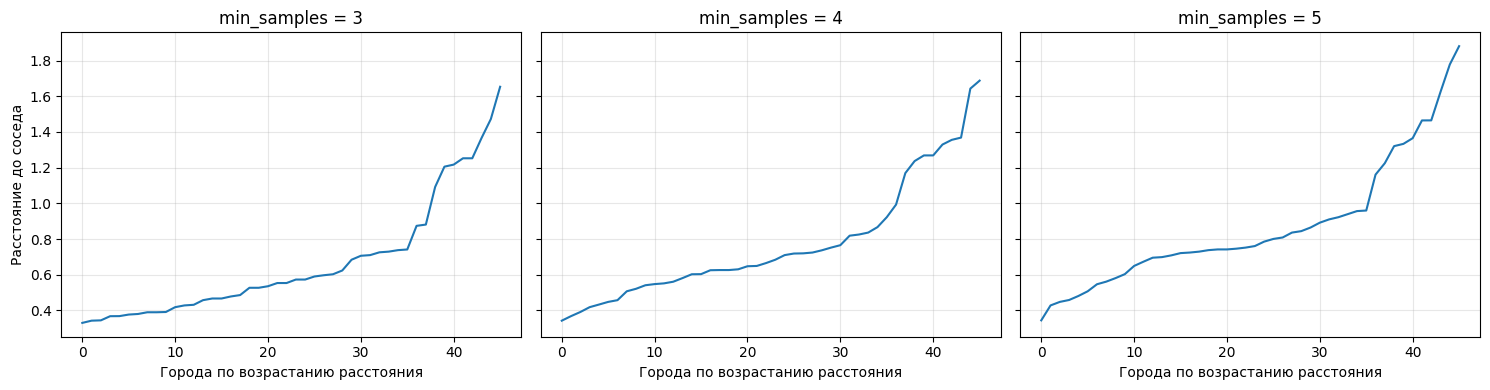

In [16]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, m in zip(axes, [3, 4, 5]):
    neighbors = NearestNeighbors(n_neighbors=m)
    neighbors.fit(X_scaled)

    distances, _ = neighbors.kneighbors(X_scaled)
    distances = np.sort(distances[:, m - 1])

    ax.plot(distances)
    ax.set_title(f"min_samples = {m}")
    ax.set_xlabel("Города по возрастанию расстояния")
    ax.grid(alpha=0.3)


axes[0].set_ylabel("Расстояние до соседа")
plt.tight_layout()
plt.show()


**Анализ графиков соседских расстояний**

На всех трёх графиках расстояния сначала увеличиваются постепенно, после чего наблюдается более резкий рост. Это указывает на переход от относительно плотных областей к более изолированным наблюдениям.

С увеличением min_samples расстояния до соответствующих соседей возрастают, поскольку для формирования плотной окрестности требуется больше объектов.

По графикам можно выделить ориентировочный диапазон eps около 0,7–1,0. При этом точка изгиба выражена не однозначно, поэтому выбрать единственное оптимальное значение только по графикам затруднительно.

Для дальнейшего обоснования параметров проведём перебор комбинаций eps и min_samples с оценкой количества кластеров, доли шума и коэффициента силуэта.

**Подбор параметров методом Grid Search**

Для выбора параметров DBSCAN проведём перебор значений eps от 0,5 до 1,3 с шагом 0,1 и min_samples от 3 до 5.

Для каждой комбинации оценим количество кластеров, размеры групп, долю шумовых объектов и коэффициент силуэта. Это позволит выбрать параметры с учётом качества разделения и количества городов, вошедших в кластеры.

In [18]:
from sklearn.metrics import silhouette_score

results = []

for m in [3, 4, 5]:
    for eps in np.round(np.arange(0.5, 1.31, 0.1), 2):

        labels = DBSCAN(
            eps=eps,
            min_samples=m
        ).fit_predict(X_scaled)

        clusters = sorted(set(labels) - {-1})
        mask = labels != -1

        n_clusters = len(clusters)
        n_noise = (~mask).sum()
        sizes = [int((labels == c).sum()) for c in clusters]

        if 2 <= n_clusters < mask.sum():
            silhouette = silhouette_score(
                X_scaled[mask],
                labels[mask]
            )
        else:
            silhouette = np.nan

        results.append({
            "eps": eps,
            "min_samples": m,
            "clusters": n_clusters,
            "noise": n_noise,
            "noise_pct": 100 * n_noise / len(labels),
            "sizes": str(sizes),
            "silhouette": silhouette
        })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,eps,min_samples,clusters,noise,noise_pct,sizes,silhouette
0,0.5,3,3,22,47.826,"[15, 3, 6]",0.484
1,0.6,3,3,13,28.261,"[16, 14, 3]",0.454
2,0.7,3,2,11,23.913,"[17, 18]",0.540
3,0.8,3,2,8,17.391,"[19, 19]",0.512
4,0.9,3,1,8,17.391,[38],NaN
5,1.0,3,1,8,17.391,[38],NaN
6,1.1,3,1,5,10.870,[41],NaN
7,1.2,3,1,4,8.696,[42],NaN
8,1.3,3,1,1,2.174,[45],NaN
9,0.5,4,1,34,73.913,[12],NaN


**Анализ результатов**

При eps = 0.8 и min_samples = 4 получены два кластера по 19 городов, 8 шумовых наблюдений (17,4%) и силуэт 0,512.

**Кластеризация с выбранными параметрами**

Применим DBSCAN с параметрами eps = 0.8 и min_samples = 4, выбранными по результатам перебора. Определим принадлежность городов к кластерам, а также выделим основные, граничные и шумовые точки.

In [20]:
dbscan = DBSCAN(eps=0.8, min_samples=4)
clusters_dbscan = dbscan.fit_predict(X_scaled)

df_dbscan = df_clean.copy()
df_dbscan["Cluster"] = clusters_dbscan

df_dbscan["Type"] = "border"
df_dbscan.loc[df_dbscan.index[dbscan.core_sample_indices_], "Type"] = "core"
df_dbscan.loc[df_dbscan["Cluster"] == -1, "Type"] = "noise"

display(df_dbscan.groupby(["Cluster", "Type"]).size())

Cluster  Type  
-1       noise      8
 0       border     3
         core      16
 1       border     4
         core      15
dtype: int64

**Результаты кластеризации**

DBSCAN выделил два кластера по 19 городов и 8 шумовых объектов. В первом кластере 16 основных и 3 граничные точки, во втором — 15 основных и 4 граничные.

Большинство городов в обоих кластерах являются основными точками, что указывает на наличие плотных областей.

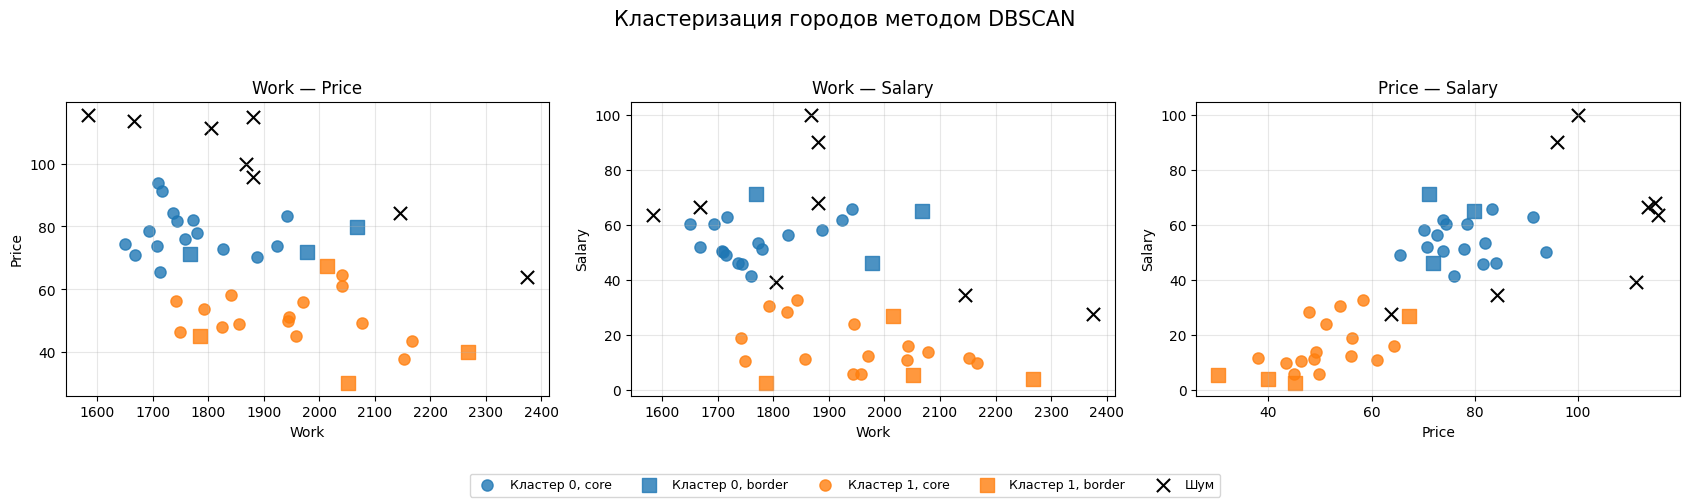

In [21]:
pairs = [
    ("Work", "Price"),
    ("Work", "Salary"),
    ("Price", "Salary")
]

colors = {0: "tab:blue", 1: "tab:orange"}
markers = {"core": "o", "border": "s"}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (x_col, y_col) in zip(axes, pairs):

    for cluster_id in [0, 1]:
        for point_type in ["core", "border"]:
            group = df_dbscan[
                (df_dbscan["Cluster"] == cluster_id) &
                (df_dbscan["Type"] == point_type)
            ]

            ax.scatter(
                group[x_col],
                group[y_col],
                color=colors[cluster_id],
                marker=markers[point_type],
                s=65 if point_type == "core" else 105,
                alpha=0.8,
                label=f"Кластер {cluster_id}, {point_type}"
            )

    noise = df_dbscan[df_dbscan["Type"] == "noise"]
    ax.scatter(
        noise[x_col],
        noise[y_col],
        color="black",
        marker="x",
        s=90,
        label="Шум"
    )

    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_title(f"{x_col} — {y_col}")
    ax.grid(alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, fontsize=9)

fig.suptitle("Кластеризация городов методом DBSCAN", fontsize=15)
plt.tight_layout(rect=[0, 0.09, 1, 0.94])
plt.show()

**Анализ результатов визуализации**

На графиках выделяются два кластера, наиболее заметно различающиеся по показателям Price и Salary. Первый кластер характеризуется более высокими значениями цен и зарплат, второй — более низкими.

Основные точки формируют плотные области, граничные располагаются преимущественно по краям кластеров. Восемь городов определены как шумовые наблюдения.

In [22]:
df_dbscan[df_dbscan["Cluster"] == -1]

,City,Work,Price,Salary,Cluster,Type
13,Geneva,1880,95.9,90.3,-1,noise
14,Helsinki,1667,113.6,66.6,-1,noise
15,Hong_Kong,2375,63.8,27.8,-1,noise
33,Oslo,1583,115.5,63.7,-1,noise
40,Stockholm,1805,111.3,39.2,-1,noise
42,Taipei,2145,84.3,34.5,-1,noise
44,Tokyo,1880,115.0,68.0,-1,noise
47,Zurich,1868,100.0,100.0,-1,noise


К выбросам отнесены преимущественно города с особенно высокими ценами или зарплатами (Цюрих, Женева, Осло), а также города с продолжительным рабочим годом (Гонконг, Тайбэй).

In [23]:
cluster_means_dbscan = (
    df_dbscan[df_dbscan["Cluster"] != -1]
    .groupby("Cluster")[features].mean().round(2))

cluster_means_dbscan


,Work,Price,Salary
Cluster,,,
0,1792.00,77.53,55.16
1,1959.21,50.12,14.79


**Интерпретация результатов DBSCAN**

Первый кластер характеризуется меньшей продолжительностью рабочего года, более высокими ценами и зарплатами. Во втором кластере наблюдается обратная тенденция: больше рабочих часов, но ниже показатели цен и зарплат.

Восемь городов, включая Geneva, Helsinki, Hong Kong и Zurich, определены как шумовые. Их сочетания экономических характеристик не соответствуют выделенным плотным группам.

Таким образом, DBSCAN позволил выделить две экономически различающиеся группы городов и отдельно определить нетипичные наблюдения.

#**Сравнение методов и общий вывод**

В работе были применены три метода кластеризации: иерархический, K-means и DBSCAN.

Все три метода выявили две группы городов с различными экономическими характеристиками. Первая группа отличается более высокими ценами и почасовыми зарплатами при меньшей продолжительности рабочего года. Вторая группа характеризуеца более низкими ценами и зарплатами, но большее количество рабочих часов.

Иерархический метод и K-means дали одинаковые средние показатели кластеров. DBSCAN также обнаружил схожее разделение, но дополнительно выделил 8 городов, что для меня явялется более интересным результатом.